# Synthetic HSI generation — step by step

Each sample is a 36×15×15 reflectance cube (the model input) and a 15×15 material
mask (the label). `src/data_generation/` builds it in the stages below; this notebook
runs them one at a time and plots the intermediate arrays. Nothing here writes files.

| stage | what happens | module |
|---|---|---|
| 0 | measured spectra resampled onto the wavelength grid | `spectral_library` |
| 1 | geometry rasterised to a **material index** per pixel | `pipeline`, `geometry` |
| 2a | blend pristine ↔ irradiated, one weight per scene | `pipeline` |
| 2b | spectral noise, one draw **per material** | `pipeline` |
| 2c | paint: extrude the mask into a cube | `pipeline` |
| 3a | per-band Gaussian blur, σ grows with λ | `pipeline` |
| 3b | sensor noise, independent per pixel and band | `pipeline` |

In code, `generate_sample(cfg, seed, lib)` runs stages 1–3 and returns a `Sample`
with every intermediate.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm, LinearSegmentedColormap

from src.data_generation import SimConfig, SpectralLibrary, ID_TO_NAME, N_CLASSES
from src.data_generation.pipeline import (generate_sample, generate_batch, satellite_scene,
                                          shapes_scene, patches_scene)

ROOT = os.path.abspath("..")            # project root, for assets/materials

S1, S2 = "#2a78d6", "#eb6834"                                        # line colours: blue, orange
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8a8f", "#e4e4e2"  # text, ticks/labels, faint lines, grid
DIV = LinearSegmentedColormap.from_list("div", [S1, "#f2f2f0", S2])  # blue-white-orange, for signed values
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
})

def bare(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)

## Configuration

All parameters live in `SimConfig`; change one with `SimConfig(name=value)` or
`cfg.with_(name=value)`. Defaults: 36 bands over 350–1000 nm, sensor noise σ = 0.02.

`fingerprint()` hashes the whole config; store it with anything you save, so results can be
traced to their settings.

In [2]:
cfg = SimConfig()
# cfg = SimConfig(lambda_min_nm=400, lambda_max_nm=1000)

print("wavelength grid :", cfg.n_bands, "bands,",
      f"{cfg.lambda_min_nm:.0f}-{cfg.lambda_max_nm:.0f} nm,",
      f"step {cfg.wavelengths_nm[1]-cfg.wavelengths_nm[0]:.6f} nm")
print("psf sigma       :", f"{cfg.psf_sigma_px[0]:.3f} -> {cfg.psf_sigma_px[-1]:.3f} px")
print("sensor noise    :", cfg.sensor_noise_std)
print("image size      :", cfg.image_size, "x", cfg.image_size)
print("scene mix       :", dict(zip(["satellite","shapes","patches"], cfg.scene_probs.round(2))))
print("classes         :", N_CLASSES, "(0 = background)")
print("fingerprint     :", cfg.fingerprint())

wavelength grid : 36 bands, 350-1000 nm, step 18.571429 nm
psf sigma       : 0.583 -> 1.667 px
sensor noise    : 0.02
image size      : 15 x 15
scene mix       : {'satellite': np.float64(0.3), 'shapes': np.float64(0.3), 'patches': np.float64(0.4)}
classes         : 47 (0 = background)
fingerprint     : ec45d4018b39


---
## Stage 0 — the spectral library

Loads measured reflectance (DHR) for 46 spacecraft materials, pristine and, for 35 of
them, electron-irradiated, and resamples it onto the band grid. The result is fixed for
the whole run; stage 2a later mixes the two states per scene:
$$s = (1-w)\,s_\text{pristine} + w\,s_\text{irradiated}, \qquad w \in [0,1]$$

In [3]:
# initialize lib

lib = SpectralLibrary(cfg, root=ROOT)
L = cfg.wavelengths_nm
print(f"{len(lib.materials)} materials, {sum(m.irradiated is not None for m in lib.materials.values())} with an irradiated trace")

<cell 5>:3: SpectralLibraryWarning: 33 values outside [0, 1] in 17 spectra on the 36-band 350-1000 nm grid: 19 severe (beyond [-0.05, 1.05]), 14 marginal.
  AZW-LAII             irradiated  2 band(s), worst  +15.55 at 350 nm
  AZJ-4020             irradiated  2 band(s), worst   -9.81 at 350 nm
  AZ-400               irradiated  1 band(s), worst   -8.30 at 350 nm
  AZ-93                pristine    1 band(s), worst   +7.21 at 350 nm
  AZ-3700              irradiated  3 band(s), worst   -5.13 at 350 nm
  AZ-2100              irradiated  1 band(s), worst   +5.13 at 350 nm
  AZW-LAII             pristine    1 band(s), worst   +4.45 at 350 nm
  AZ-93                irradiated  1 band(s), worst   +3.77 at 350 nm
  AZ-2100              pristine    2 band(s), worst   +2.62 at 350 nm
  AZ-2000              irradiated  2 band(s), worst   +2.57 at 350 nm
  ... and 7 more spectra

Severe values are scan-edge artifacts (DHR is a ratio of two near-zero signals there); marginal ones are calibration of

<cell 5>:3: SpectralLibraryWarning: 8 grid bands in 2 spectra lie past the measured scan on the 36-band 350-1000 nm grid:
  Mylar_aluminized     irradiated  4 band(s) below 430 nm (up to 80 nm away), held at the first value
  Mylar_aluminized     pristine    4 band(s) below 430 nm (up to 80 nm away), held at the first value

These values are extrapolated, not measured; to avoid them use lambda_min_nm >= 421.
lib.plot_materials("unmeasured") shows them.


46 materials, 35 with an irradiated trace


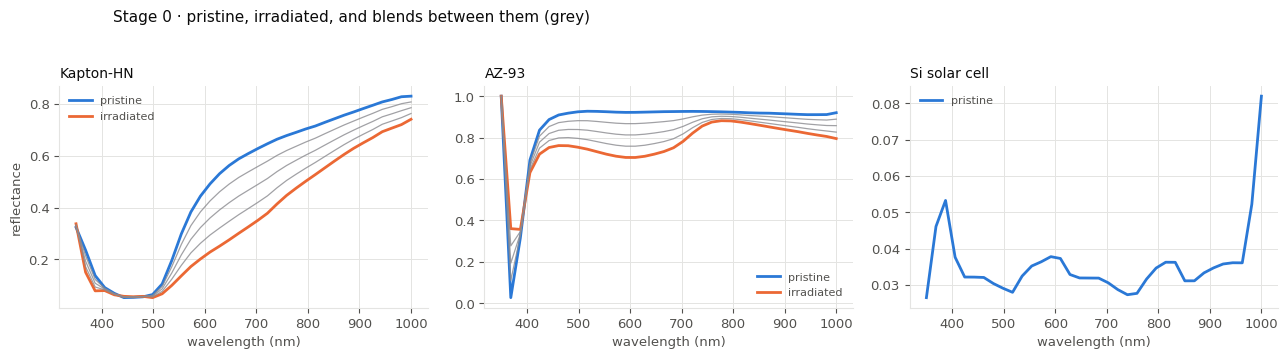

In [4]:
# plot materials from the library
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, name in zip(axes, ["Kapton-HN", "AZ-93", "Si solar cell"]):
    m = lib.materials[name]
    ax.plot(L, m.pristine, color=S1, lw=2, label="pristine")
    if m.irradiated is not None:
        ax.plot(L, m.irradiated, color=S2, lw=2, label="irradiated")
        for w in (0.25, 0.5, 0.75):
            ax.plot(L, lib.blend(name, w), color=MUTED, lw=0.9, alpha=0.8)
    ax.set_title(name, fontsize=10, loc="left")
    ax.set_xlabel("wavelength (nm)"); ax.grid(True)
    ax.legend(frameon=False, fontsize=8, labelcolor=INK2)
axes[0].set_ylabel("reflectance")
fig.suptitle("Stage 0 · pristine, irradiated, and blends between them (grey)",
             y=1.04, fontsize=11, x=0.09, ha="left")
plt.tight_layout(); plt.show()

**Note.** The library checks every resampled value and warns about values outside
[0, 1] (`on_invalid`) and grid bands outside a sheet's scan (`on_unmeasured`); each
warning says what to do about them. `lib.plot_materials(...)` plots the materials
concerned; below, all flagged ones.

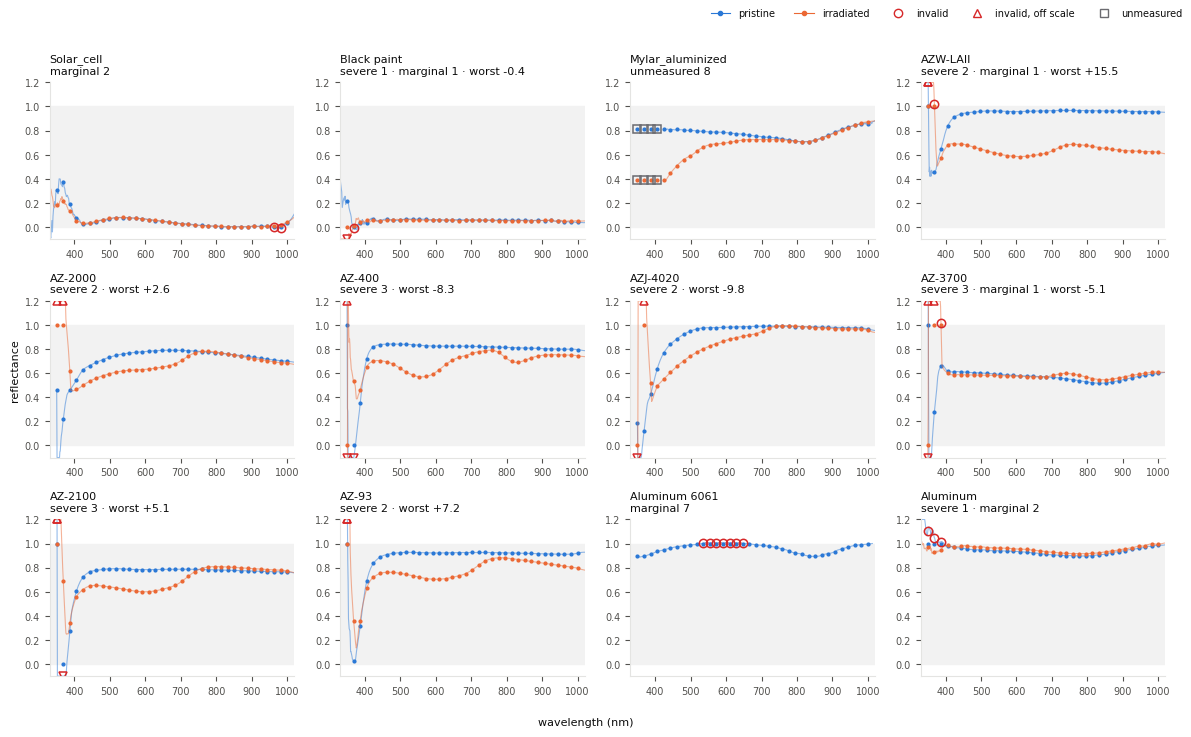

In [5]:
lib.plot_materials("flagged")   # or names, a group, "severe", "marginal", "unmeasured", "all"
plt.show()

---
## Stage 1 — the scene mask

Draws one scene and writes a material id into each pixel (0 = background); this mask
is the training label. A scene is a satellite (30%: one of two layouts in a random pose,
rendered with a pinhole camera, each part wearing a material from its own group), a few
large shapes (30%), or 12–15 small square patches (40%).

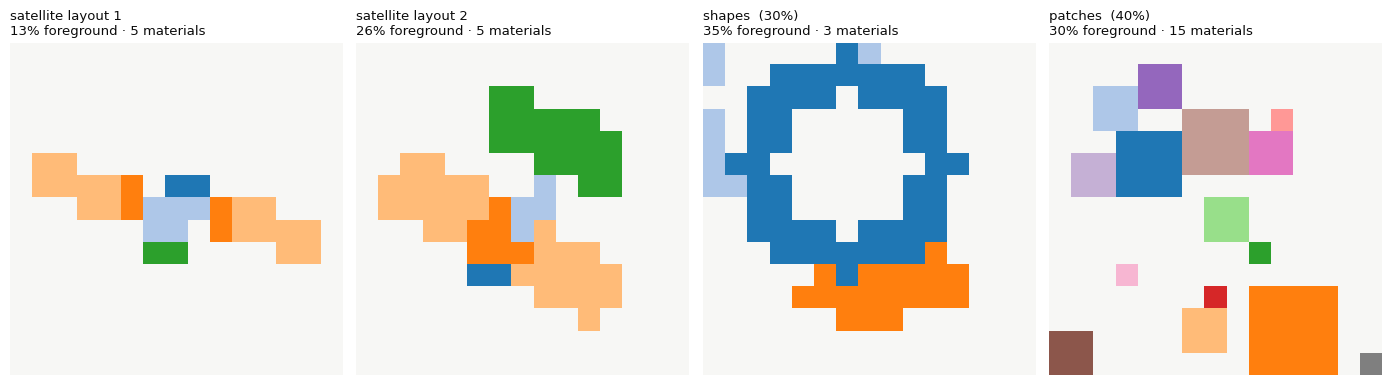

In [6]:
def show_mask(ax, mask, title):
    ids = [int(i) for i in np.unique(mask) if i]
    cols = ["#f7f7f5"] + [plt.cm.tab20(i % 20) for i in range(len(ids))]
    lut = np.zeros(int(mask.max()) + 1, int)
    for k, i in enumerate(ids): lut[i] = k + 1
    ax.imshow(lut[mask], cmap=ListedColormap(cols), vmin=0, vmax=len(ids),
              interpolation="nearest")
    bare(ax)
    ax.set_title(f"{title}\n{(mask!=0).mean():.0%} foreground · {len(ids)} materials",
                 fontsize=9.5, loc="left")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
show_mask(axes[0], satellite_scene(cfg, np.random.default_rng(3), variant=0)[0],
          "satellite layout 1")
show_mask(axes[1], satellite_scene(cfg, np.random.default_rng(3), variant=1)[0],
          "satellite layout 2")
show_mask(axes[2], shapes_scene(cfg, np.random.default_rng(3))[0], "shapes  (30%)")
show_mask(axes[3], patches_scene(cfg, np.random.default_rng(3))[0], "patches  (40%)")
plt.tight_layout(); plt.show()

**Note.** At 15×15 the satellite is under-sampled: the bus is about 1 px wide and the
antenna less. They show up only because the default `rasterizer="cv2"` fills such
slivers generously, as the original did; `SimConfig(image_size=60, rasterizer="exact")`
renders the satellite at 60×60 with exact coverage.

---
## Stages 2a–2c — from mask to cube

Once the scene mask exists, each material in it gets one spectrum, which is painted
into its pixels. This takes three steps: blend pristine and irradiated with the scene's
weight $w$ (2a), add one noise draw per material, $\mathcal{N}(0,\,(0.5\,\mathrm{std}\,s)^2)$ (2b),
and copy each spectrum along the wavelength axis at every pixel of its material (2c).

In [7]:
s = generate_sample(cfg, 3, lib, scene="satellite")
print(s.summary())

Sample(seed=3, kind=satellite)
  grid            36 bands, 350.0-1000.0 nm (step 18.5714 nm)
  mask            (15, 15) uint8, ids [3, 6, 25, 32, 45]
  cube            (36, 15, 15) float64  <- model input
  foreground      24.4%   object span 12 px
  blend weight    w = 0.433 (shared by all materials)
  psf sigma       0.583 -> 1.667 px
  sensor noise    sigma = 0.02
  value range     clean [0.000, 1.000]  -> input [-0.066, 0.852]
  materials       3:Melinex, 6:Kapton-MT, 25:AZ-93, 32:CMX, 45:Copper


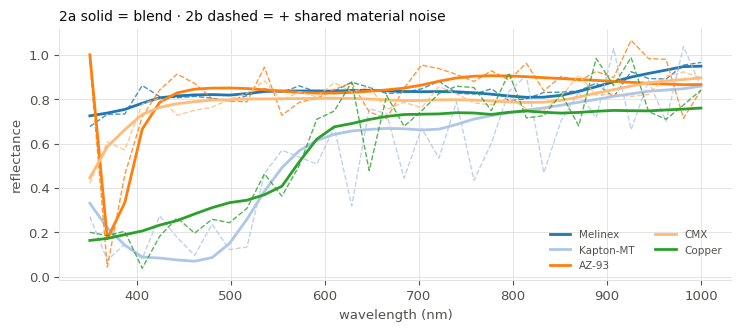

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
cols = [plt.cm.tab20(i % 20) for i in range(len(s.material_ids))]
for c, mid in zip(cols, s.material_ids):
    ax.plot(L, s.spectra_clean[mid], color=c, lw=2, label=ID_TO_NAME[mid])
    ax.plot(L, s.spectra_noisy[mid], color=c, lw=1, ls="--", alpha=0.8)
ax.set_title("2a solid = blend · 2b dashed = + shared material noise", fontsize=10, loc="left")
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("reflectance"); ax.grid(True)
ax.legend(frameon=False, fontsize=7.5, labelcolor=INK2, ncol=2)
plt.tight_layout(); plt.show()

**Note.** The 2b noise is one draw per material, shared by all its pixels, so it does
not average out over a region the way the 3b sensor noise does.

---
## Stages 3a–3b — degradation

Turns the clean cube into the model input in two steps: a Gaussian blur per band whose
width grows with wavelength, from the diffraction limit of a 3.6 m telescope (3a; σ goes
from 0.58 to 1.67 px on the default grid), then independent noise per pixel and band (3b).
The rows below show the cube after each step.

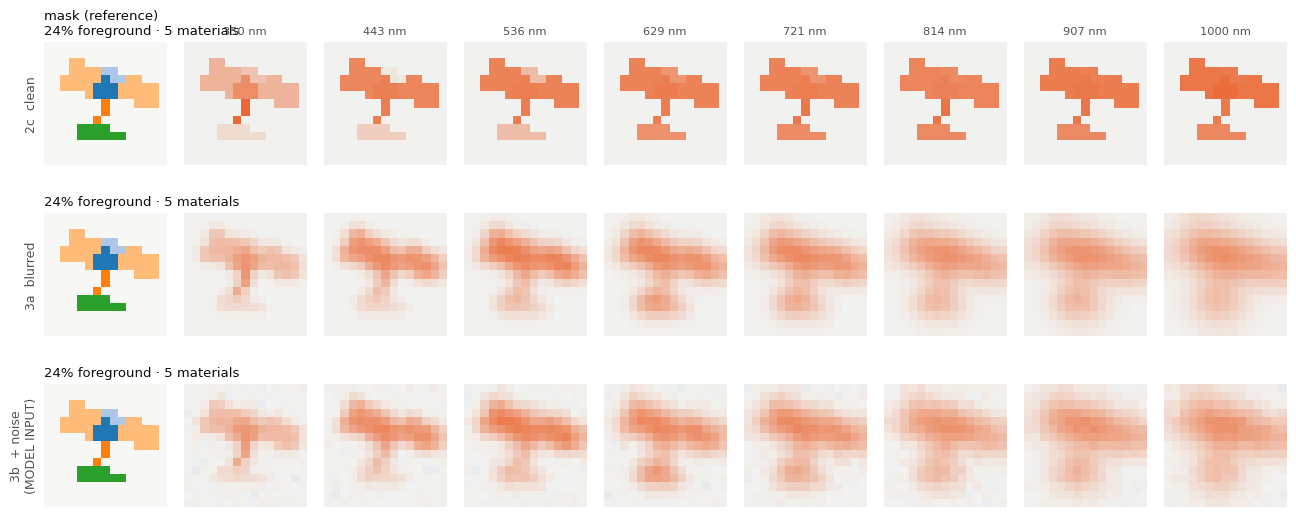

In [9]:
show = [0, 5, 10, 15, 20, 25, 30, 35]
vmax = max(abs(s.cube.min()), s.cube.max(), s.cube_clean.max())
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

fig, axes = plt.subplots(3, len(show)+1, figsize=(1.45*(len(show)+1), 5.4))
rows = [(s.cube_clean,   "2c  clean"),
        (s.cube_blurred, "3a  blurred"),
        (s.cube,         "3b  + noise\n(MODEL INPUT)")]
for r, (arr, lab) in enumerate(rows):
    show_mask(axes[r, 0], s.mask, "" if r else "mask (reference)")
    for c, j in enumerate(show):
        ax = axes[r, c+1]
        ax.imshow(arr[j], cmap=DIV, norm=norm, interpolation="nearest"); bare(ax)
        if r == 0: ax.set_title(f"{L[j]:.0f} nm", fontsize=8.2, color=INK2)
    axes[r, 0].set_ylabel(lab, fontsize=9, color=INK2)
plt.tight_layout(); plt.show()

**Note.** The blur is the only step that mixes neighbouring pixels. Its width grows with
wavelength, so a pixel near a region edge takes in more of its neighbours' spectra at long
wavelengths than at short ones.

---
## Output

`generate_sample` returns the cube, the mask and every intermediate (`s.summary()` above
lists them). Below: the spectra the model receives at one pixel per material, and scene
statistics over 150 scenes of each type.

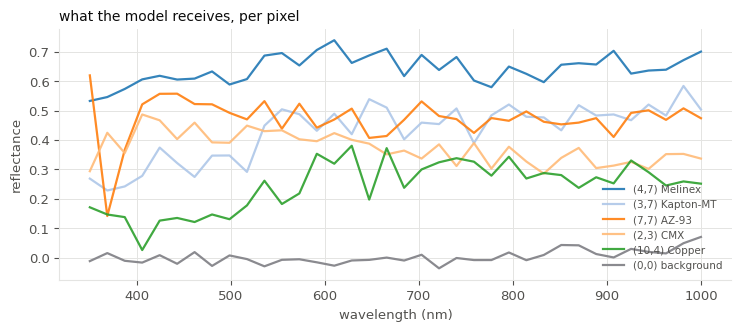

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
cols = [plt.cm.tab20(i % 20) for i in range(len(s.material_ids))]
for c, mid in zip(cols, s.material_ids):          # one pixel per material
    ys, xs = np.where(s.mask == mid)
    ax.plot(L, s.cube[:, ys[0], xs[0]], lw=1.6, color=c, alpha=0.9,
            label=f"({ys[0]},{xs[0]}) {ID_TO_NAME[mid]}")
ax.plot(L, s.cube[:, 0, 0], lw=1.6, color=MUTED, label="(0,0) background")
ax.set_title("what the model receives, per pixel", fontsize=10, loc="left")
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("reflectance"); ax.grid(True)
ax.legend(frameon=False, fontsize=7.5, labelcolor=INK2)
plt.tight_layout(); plt.show()

In [11]:
for scene in ["satellite", "shapes", "patches"]:
    B = generate_batch(cfg, lib, 150, seed0=0, scene=scene)
    B = [b for b in B if b.foreground_fraction > 0]
    print(f"{scene:10s} fg {np.mean([b.foreground_fraction for b in B]):5.1%}"
          f"   span {np.mean([b.object_span_px for b in B]):4.1f} px"
          f"   materials/scene {np.mean([len(b.material_ids) for b in B]):4.1f}")

satellite  fg 20.8%   span 12.4 px   materials/scene  4.9
shapes     fg 23.1%   span 11.6 px   materials/scene  2.1
patches    fg 33.9%   span 14.8 px   materials/scene 13.6


---
## Decisions

| default | why |
|---|---|
| `clip_reflectance=True`, with a warning | the sheets carry artifacts (−9.8 … +15.5 at 350 nm); the warning says how far to trim the grid instead |
| `extrapolate_red="hold"` | filling with 0 makes a material identifiable by where its scan stops |
| `rasterizer="cv2"` | it fills sub-pixel parts generously, which is what the trained models saw |
| real triangles, unique patch labels, edge faces clipped | the original's triangles had 2 points (so they were lines), its patch labels were redrawn at random, and it skipped faces touching the frame |
| scene type drawn 30/30/40 (`p_satellite`, `p_shapes`, `p_patches`) | the original's mix |
| one blend weight per scene | as in the original; `blend_weight_per_material=True` draws one per material |

## Limits of the simulated data

- **Reflectance only:** no solar spectrum, atmosphere or instrument response, so a real radiance cube needs those divided out first.
- **Sensor noise is additive and white** (the same σ at every band and brightness); real noise grows with the signal, and the atmosphere acts multiplicatively and varies with wavelength.
- **No viewing geometry in the radiometry:** a panel has the same spectrum at any angle.
- **The grid stops at 1000 nm** while 44 of 46 sheets reach ~2500 nm. Adding 2000–2500 nm more than doubles the median distance from a material to its nearest neighbour (RMS 0.056 → 0.13); 1000–2000 nm adds little.
- **The satellite is under-sampled:** at 15×15 most parts are 1–2 px.
- **11 materials have no irradiated spectrum** and ignore $w$; `require_irradiated=True` drops them.